# **PERSONAL PROJECT - FINANCIAL FRAUD**
#### Date: June 2026 - October 2026

## **I. Project Overview**
### **1. Overview**
The primary aim of this project is to build a machine learning model capable of detecting fraudulent transactions in real-time while minimising false positives, <br>
and exposing the trained pipeline through a REST API.<br>

### **2. Objectives**
1. Exploratory Data Analysis (EDA):
   * Inspect transaction distributions, amounts, and temporal trends.
   * Quantify class imbalance (typically < 1% positive fraud cases).

2. Data Preprocessing & Handling Class Imbalance:
   * Scale numerical features safely without introducing data leakage.
   * Implement sampling techniques or cost-sensitive learning to address severe label imbalance.

3. Model Training & Evaluation:
   * Benchmark multiple algorithms (Logistic Regression, Random Forest, XGBoost).
   * Evaluate models using metrics.

4. Software Engineering & Cloud Deployment:
   * Wrap the inference pipeline into a lightweight API using **FastAPI** / **Flask**.
   * Containerize the service using **Docker** for cloud deployment.

### **3. Data Collection**
This project utilised the Financial Transactions Dataset: Analytics created by Computing Victor on Kaggle. <br>This is a relational dataset split into multiple components that must be intergrated for a comprehensive fraud detection modeling. <br>Link: 
__[Financial Transactions Dataset: Analytics](https://www.kaggle.com/datasets/computingvictor/transactions-fraud-datasets)__<br>

**Dataset Components:**
1. `transactions_data.csv`: Detailed records containing transaction amounts, timestamps, and merchant details.
2. `cards_dat.csv`: Card metadata including card limits, types, and account mappings.
3. `mcc_codes.json`: Merchant Category Codes describing business types.
4. `train_fraud_labels.json`: Ground-truth target labels (Binary: 0 = legitimate, 1 = fraudulent).
5. `users_data` Customer demographic and account-level profiles.

**Anticipated Data Challenges & Strategy:**
1. Data Integration: Requires merging disparate tables using keys like `user_id` and `card_id`.
2. Class Imbalance: Expected low percentage of fraud cases, requiring careful handling via evaluation metrics like Precision-Recall AUC and resampling strategies.
3. Temporal Patterns: Timestamps span across the 2010s, allowing for time-based feature extraction (e.g., time of day, day of week).

## **I. Data Preparation and Handling:**

### **1. Extract and Clean Datasets**

In [48]:
%pip install folium
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import folium
import sklearn
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from folium.plugins import HeatMap
import warnings
warnings.filterwarnings('ignore')
import re

Note: you may need to restart the kernel to use updated packages.


**Transaction Data**

In [3]:
#Load the dataset 
transactions = pd.read_csv('transactions_data.csv')

In [4]:
#Preview the dataset
transactions.info()
transactions.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 13305915 entries, 0 to 13305914
Data columns (total 12 columns):
 #   Column          Dtype  
---  ------          -----  
 0   id              int64  
 1   date            str    
 2   client_id       int64  
 3   card_id         int64  
 4   amount          str    
 5   use_chip        str    
 6   merchant_id     int64  
 7   merchant_city   str    
 8   merchant_state  str    
 9   zip             float64
 10  mcc             int64  
 11  errors          str    
dtypes: float64(1), int64(5), str(6)
memory usage: 1.2 GB


,id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
0,7475327,2010-01-01 00:01:00,1556,2972,$-77.00,Swipe Transaction,59935,Beulah,ND,58523.0,5499,NaN
1,7475328,2010-01-01 00:02:00,561,4575,$14.57,Swipe Transaction,67570,Bettendorf,IA,52722.0,5311,NaN
2,7475329,2010-01-01 00:02:00,1129,102,$80.00,Swipe Transaction,27092,Vista,CA,92084.0,4829,NaN
3,7475331,2010-01-01 00:05:00,430,2860,$200.00,Swipe Transaction,27092,Crown Point,IN,46307.0,4829,NaN
4,7475332,2010-01-01 00:06:00,848,3915,$46.41,Swipe Transaction,13051,Harwood,MD,20776.0,5813,NaN
5,7475333,2010-01-01 00:07:00,1807,165,$4.81,Swipe Transaction,20519,Bronx,NY,10464.0,5942,NaN
6,7475334,2010-01-01 00:09:00,1556,2972,$77.00,Swipe Transaction,59935,Beulah,ND,58523.0,5499,NaN
7,7475335,2010-01-01 00:14:00,1684,2140,$26.46,Online Transaction,39021,ONLINE,NaN,NaN,4784,NaN
8,7475336,2010-01-01 00:21:00,335,5131,$261.58,Online Transaction,50292,ONLINE,NaN,NaN,7801,NaN
9,7475337,2010-01-01 00:21:00,351,1112,$10.74,Swipe Transaction,3864,Flushing,NY,11355.0,5813,NaN


**Cards Data**

In [5]:
#Load the dataset
cards = pd.read_csv('cards_data.csv')

In [6]:
#Preview the dataset
cards.info()
cards.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 6146 entries, 0 to 6145
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   id                     6146 non-null   int64
 1   client_id              6146 non-null   int64
 2   card_brand             6146 non-null   str  
 3   card_type              6146 non-null   str  
 4   card_number            6146 non-null   int64
 5   expires                6146 non-null   str  
 6   cvv                    6146 non-null   int64
 7   has_chip               6146 non-null   str  
 8   num_cards_issued       6146 non-null   int64
 9   credit_limit           6146 non-null   str  
 10  acct_open_date         6146 non-null   str  
 11  year_pin_last_changed  6146 non-null   int64
 12  card_on_dark_web       6146 non-null   str  
dtypes: int64(6), str(7)
memory usage: 624.3 KB


,id,client_id,card_brand,card_type,card_number,expires,cvv,has_chip,num_cards_issued,credit_limit,acct_open_date,year_pin_last_changed,card_on_dark_web
0,4524,825,Visa,Debit,4344676511950444,12/2022,623,YES,2,$24295,09/2002,2008,No
1,2731,825,Visa,Debit,4956965974959986,12/2020,393,YES,2,$21968,04/2014,2014,No
2,3701,825,Visa,Debit,4582313478255491,02/2024,719,YES,2,$46414,07/2003,2004,No
3,42,825,Visa,Credit,4879494103069057,08/2024,693,NO,1,$12400,01/2003,2012,No
4,4659,825,Mastercard,Debit (Prepaid),5722874738736011,03/2009,75,YES,1,$28,09/2008,2009,No
5,4537,1746,Visa,Credit,4404898874682993,09/2003,736,YES,1,$27500,09/2003,2012,No
6,1278,1746,Visa,Debit,4001482973848631,07/2022,972,YES,2,$28508,02/2011,2011,No
7,3687,1746,Mastercard,Debit,5627220683410948,06/2022,48,YES,2,$9022,07/2003,2015,No
8,3465,1746,Mastercard,Debit (Prepaid),5711382187309326,11/2020,722,YES,2,$54,06/2010,2015,No
9,3754,1746,Mastercard,Debit (Prepaid),5766121508358701,02/2023,908,YES,1,$99,07/2006,2012,No


**Users Data**

In [6]:
#Load the dataset
users = pd.read_csv('users_data.csv')

In [8]:
#Check the information and summary statistics of the dataset
users.info()
users.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 2000 non-null   int64  
 1   current_age        2000 non-null   int64  
 2   retirement_age     2000 non-null   int64  
 3   birth_year         2000 non-null   int64  
 4   birth_month        2000 non-null   int64  
 5   gender             2000 non-null   str    
 6   address            2000 non-null   str    
 7   latitude           2000 non-null   float64
 8   longitude          2000 non-null   float64
 9   per_capita_income  2000 non-null   str    
 10  yearly_income      2000 non-null   str    
 11  total_debt         2000 non-null   str    
 12  credit_score       2000 non-null   int64  
 13  num_credit_cards   2000 non-null   int64  
dtypes: float64(2), int64(7), str(5)
memory usage: 218.9 KB


,id,current_age,retirement_age,birth_year,birth_month,gender,address,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
0,825,53,66,1966,11,Female,462 Rose Lane,34.15,-117.76,$29278,$59696,$127613,787,5
1,1746,53,68,1966,12,Female,3606 Federal Boulevard,40.76,-73.74,$37891,$77254,$191349,701,5
2,1718,81,67,1938,11,Female,766 Third Drive,34.02,-117.89,$22681,$33483,$196,698,5
3,708,63,63,1957,1,Female,3 Madison Street,40.71,-73.99,$163145,$249925,$202328,722,4
4,1164,43,70,1976,9,Male,9620 Valley Stream Drive,37.76,-122.44,$53797,$109687,$183855,675,1
5,68,42,70,1977,10,Male,58 Birch Lane,41.55,-90.60,$20599,$41997,$0,704,3
6,1075,36,67,1983,12,Female,5695 Fifth Street,38.22,-85.74,$25258,$51500,$102286,672,3
7,1711,26,67,1993,12,Male,1941 Ninth Street,45.51,-122.64,$26790,$54623,$114711,728,1
8,1116,81,66,1938,7,Female,11 Spruce Avenue,40.32,-75.32,$26273,$42509,$2895,755,5
9,1752,34,60,1986,1,Female,887 Grant Street,29.97,-92.12,$18730,$38190,$81262,810,1


### **2. Read JSON Files**

In [7]:
#Load fraud labels
with open("train_fraud_labels.json", "r") as f:
    fraud_data = json.load(f)
labels_dict = fraud_data['target']
fraud_labels = pd.DataFrame(list(labels_dict.items()), columns=["fraud_id", "is_fraud"])
fraud_labels['fraud_id'] = pd.to_numeric(fraud_labels['fraud_id'], errors='coerce')

#Load the Merchant Category Codes
with open("mcc_codes.json", "r") as f:
    mcc_data = json.load(f)
mcc_codes = pd.DataFrame(list(mcc_data.items()), columns=["mcc", "description"])

#Preview 
print("Fraud Labels:")
print(fraud_labels.head(10))

print("\nMCC Codes:")
print(mcc_codes.head(10))

Fraud Labels:
   fraud_id is_fraud
0  10649266       No
1  23410063       No
2   9316588       No
3  12478022       No
4   9558530       No
5  12532830       No
6  19526714       No
7   9906964       No
8  13224888       No
9  13749094       No

MCC Codes:
    mcc                                 description
0  5812               Eating Places and Restaurants
1  5541                            Service Stations
2  7996        Amusement Parks, Carnivals, Circuses
3  5411                Grocery Stores, Supermarkets
4  4784                       Tolls and Bridge Fees
5  4900  Utilities - Electric, Gas, Water, Sanitary
6  5942                                 Book Stores
7  5814                       Fast Food Restaurants
8  4829                              Money Transfer
9  5311                           Department Stores


### **3. Handling Data**

In [10]:
#Check for missing values and duplicate rows in the dataset
missing_values = transactions.isnull().sum()
print(f'Missing values:\n{missing_values}')

duplicate_rows = transactions.duplicated().sum()
print(f'\nNumber of duplicate rows: {duplicate_rows}')

Missing values:
id                       0
date                     0
client_id                0
card_id                  0
amount                   0
use_chip                 0
merchant_id              0
merchant_city            0
merchant_state     1563700
zip                1652706
mcc                      0
errors            13094522
dtype: int64

Number of duplicate rows: 0


Notice there are three features having significant missing values: `merchant_state`,`zip`, and `errors`. The underlying cause is understandable:
- `merchant_state` and `zip`: frequently missing for online, digital, or international transactions where no physical terminal adress is recorded. 
- `errors`: errors are only recorded when a transaction fails or is declined. Therefore, successful and approved transactions while be left empty. 

To tackle this problem, binary indicators will be created to capture whether a location is missing (indicating online/international transaction) or if an error occured. 

In [8]:
#Create binary indicator variable for location and errors
transactions['unknown_location'] = transactions['merchant_state'].isna().astype(int)
transactions['has_errors'] = transactions['errors'].isna().astype(int)

#Fill missing values 
transactions['merchant_state'] = transactions['merchant_state'].fillna('UNKNOWN')
transactions['zip'] = transactions['zip'].fillna('UNKNOWN')
transactions['errors'] = transactions['errors'].fillna('NONE')

In [ ]:
#Check again for missing values and duplicate rows in the dataset
missing_values = transactions.isnull().sum()
print(f'Missing values:\n{missing_values}')

duplicate_rows = transactions.duplicated().sum()
print(f'\nNumber of duplicate rows: {duplicate_rows}')

Certain columns should be converted to appropriate data types for better analysis and modeling.<br>
Noticing the `amount` attributes are strings. Convert the attributes from strings to numeric values will be helpful to analyse and train the model. 

In [9]:
clean_amounts = (transactions['amount'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False))
transactions['amount'] = pd.to_numeric(clean_amounts, errors='coerce')

print('Min amount:', transactions['amount'].min())
print('Max amount:', transactions['amount'].max())
print('Total valid numeric rows:',transactions['amount'].dropna().count())

Min amount: -500.0
Max amount: 6820.2
Total valid numeric rows: 13305915


For `mcc` in **transactions** and **mcc_codes**, `yearly_income` in **users**, and `credit_limit` in **cards**: These attributes need to be converted for merging between datasets, analysing and modeling.

In [10]:
#Convert mcc to string type for merging and consistency
transactions['mcc'] = transactions['mcc'].astype(str)
mcc_codes['mcc'] = mcc_codes['mcc'].astype(str)

#Convert yearly_income and credit_limit to numeric type for analysis
users['yearly_income'] = (users['yearly_income'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False))
users['yearly_income'] = pd.to_numeric(users['yearly_income'], errors='coerce')

cards['credit_limit'] = (cards['credit_limit'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False))
cards['credit_limit'] = pd.to_numeric(cards['credit_limit'], errors='coerce')

### **4. Merging Data**

In [11]:
#Merge the datasets 
df = transactions.merge(cards, left_on='card_id', right_on='id', how='left')
df = df.merge(users, left_on='client_id_x', right_on='id', how='left')
df = df.merge(mcc_codes, on='mcc', how='left')
df = df.merge(fraud_labels, left_on='id_x', right_on='fraud_id', how='left')
df.head(10)

,id_x,date,client_id_x,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,...,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards,description,fraud_id,is_fraud
0,7475327,2010-01-01 00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.0,...,46.80,-100.76,$23679,48277,$110153,740,4,Miscellaneous Food Stores,7475327.0,No
1,7475328,2010-01-01 00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.0,...,40.80,-91.12,$18076,36853,$112139,834,5,Department Stores,7475328.0,No
2,7475329,2010-01-01 00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.0,...,33.18,-117.29,$16894,34449,$36540,686,3,Money Transfer,7475329.0,No
3,7475331,2010-01-01 00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.0,...,41.42,-87.35,$26168,53350,$128676,685,5,Money Transfer,NaN,NaN
4,7475332,2010-01-01 00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.0,...,38.86,-76.60,$33529,68362,$96182,711,2,Drinking Places (Alcoholic Beverages),7475332.0,No
5,7475333,2010-01-01 00:07:00,1807,165,4.81,Swipe Transaction,20519,Bronx,NY,10464.0,...,40.84,-73.87,$25537,52065,$98613,828,5,Book Stores,7475333.0,No
6,7475334,2010-01-01 00:09:00,1556,2972,77.00,Swipe Transaction,59935,Beulah,ND,58523.0,...,46.80,-100.76,$23679,48277,$110153,740,4,Miscellaneous Food Stores,NaN,NaN
7,7475335,2010-01-01 00:14:00,1684,2140,26.46,Online Transaction,39021,ONLINE,UNKNOWN,UNKNOWN,...,36.34,-83.28,$13668,27861,$108313,782,5,Tolls and Bridge Fees,7475335.0,No
8,7475336,2010-01-01 00:21:00,335,5131,261.58,Online Transaction,50292,ONLINE,UNKNOWN,UNKNOWN,...,26.74,-80.12,$27696,56467,$66565,688,3,"Athletic Fields, Commercial Sports",NaN,NaN
9,7475337,2010-01-01 00:21:00,351,1112,10.74,Swipe Transaction,3864,Flushing,NY,11355.0,...,40.77,-73.84,$13810,17150,$375,807,6,Drinking Places (Alcoholic Beverages),NaN,NaN


In [12]:
# Convert the 'is_fraud' column to a numeric format for analysis
df['is_fraud_numeric'] = df['is_fraud'].map({'No': 0, 'Yes': 1})

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13305915 entries, 0 to 13305914
Data columns (total 46 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   id_x                   int64  
 1   date                   str    
 2   client_id_x            int64  
 3   card_id                int64  
 4   amount                 float64
 5   use_chip               str    
 6   merchant_id            int64  
 7   merchant_city          str    
 8   merchant_state         str    
 9   zip                    object 
 10  mcc                    str    
 11  errors                 str    
 12  unknown_location       int64  
 13  has_errors             int64  
 14  id_y                   int64  
 15  client_id_y            int64  
 16  card_brand             str    
 17  card_type              str    
 18  card_number            int64  
 19  expires                str    
 20  cvv                    int64  
 21  has_chip               str    
 22  num_cards_issued       int6

### **5. Extract Data**

In [13]:
#Extract data for 'is_fraud_numeric' == 1 (fraudulent transactions)
fraud_df = df[df['is_fraud_numeric'] == 1].copy()

In [20]:
fraud_df.info()

<class 'pandas.DataFrame'>
Index: 13332 entries, 3459 to 13289605
Data columns (total 45 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_x                   13332 non-null  int64  
 1   date                   13332 non-null  str    
 2   client_id_x            13332 non-null  int64  
 3   card_id                13332 non-null  int64  
 4   amount                 13332 non-null  float64
 5   use_chip               13332 non-null  str    
 6   merchant_id            13332 non-null  int64  
 7   merchant_city          13332 non-null  str    
 8   merchant_state         13332 non-null  str    
 9   zip                    13332 non-null  object 
 10  mcc                    13332 non-null  str    
 11  errors                 13332 non-null  str    
 12  unknown_location       13332 non-null  int64  
 13  has_errors             13332 non-null  int64  
 14  id_y                   13332 non-null  int64  
 15  client_id_y 

## **III. Exploratory Data Analysis (EDA)**

### **1. Univariate EDA - Explore Distributions**

In [ ]:
import matplotlib.ticker as ticker

#### **Users**

Text(0, 0.5, 'Count')

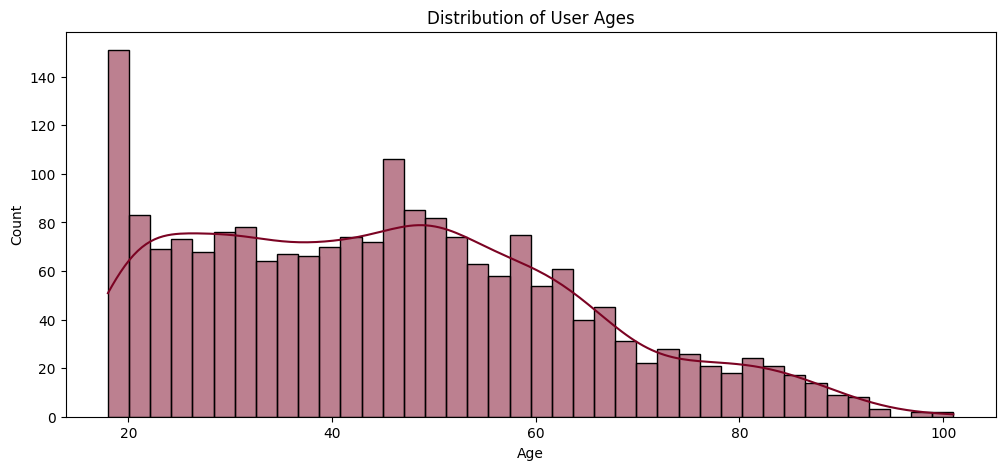

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(users['current_age'], bins=40, kde=True, color='#7b0323', ax=ax)
ax.set_title('Distribution of User Ages')
ax.set_xlabel('Age')
ax.set_ylabel('Count')

There is a **bimodal tendency** seen from the histogram. People from a wide range of 20 to 100 years old use bank transactions. A large amount of users is around **20 years old**. With two peaks in 25-30 years old range and 45-50 years old range, the distribution decrease modestly from 60 years old forward. This is common in bank transactions. 

Text(0, 0.5, 'Customer Age')

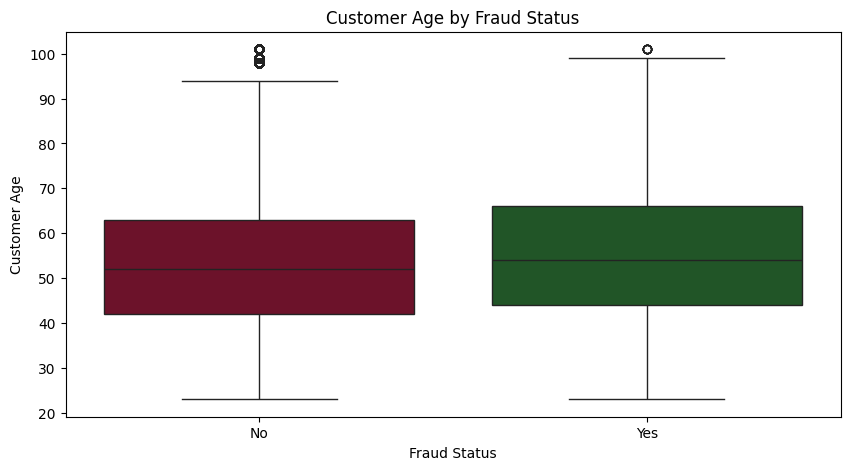

In [ ]:
#Customer Age by Fraud Status
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x='is_fraud', y='current_age', data=df, ax=ax, palette={'No': '#7b0323', 'Yes': "#195d20"})
ax.set_title('Customer Age by Fraud Status')
ax.set_xlabel('Fraud Status')
ax.set_ylabel('Customer Age')  

#### **Cards**

(array([0, 1, 2]),
 [Text(0, 0, 'Debit'), Text(1, 0, 'Credit'), Text(2, 0, 'Debit (Prepaid)')])

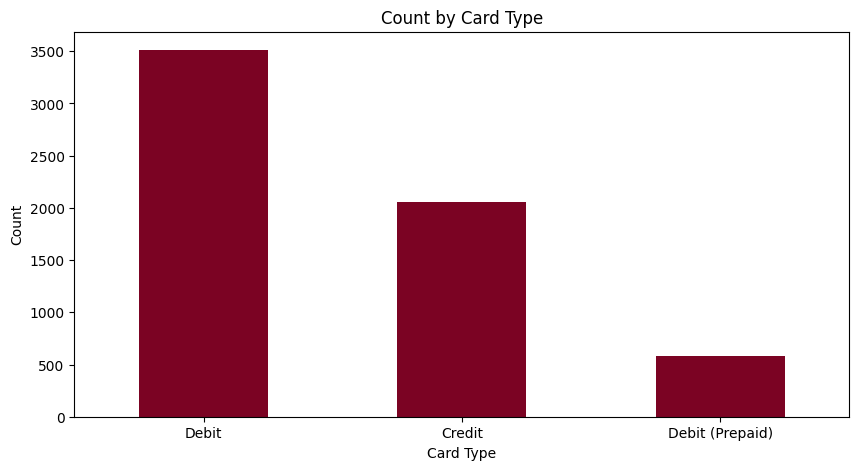

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
cards['card_type'].value_counts().plot(kind='bar', color='#7b0323', ax=ax)
ax.set_title('Count by Card Type')
ax.set_xlabel('Card Type')
ax.set_ylabel('Count')
plt.xticks(rotation=0)

The dataset is **heavily imbalanced toward standard Debit cards**, which account for more than half of the total observations.

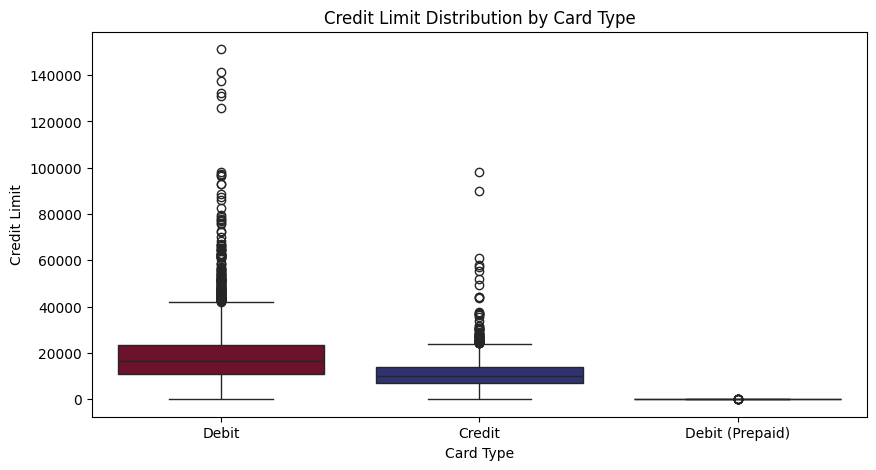

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x=cards['card_type'], y=cards['credit_limit'], ax=ax,
            palette={'Debit': '#7b0323', 'Credit': "#25297B", 'Debit (Prepaid)': "#7b6969"})
ax.set_title('Credit Limit Distribution by Card Type')
ax.set_xlabel('Card Type')
ax.set_ylabel('Credit Limit')
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=10)) 

- Debit: Shows a wide interquartile range without outliers in this plot.
- Credit: Features a higher median credit limit compared to standard Debit cards, along with several lower-range outliers below the lower whisker.
- Debit (Prepaid): Shows a relatively high median credit limit (similar to Credit), with a spread of several lower-range outliers.

#### **Transaction**

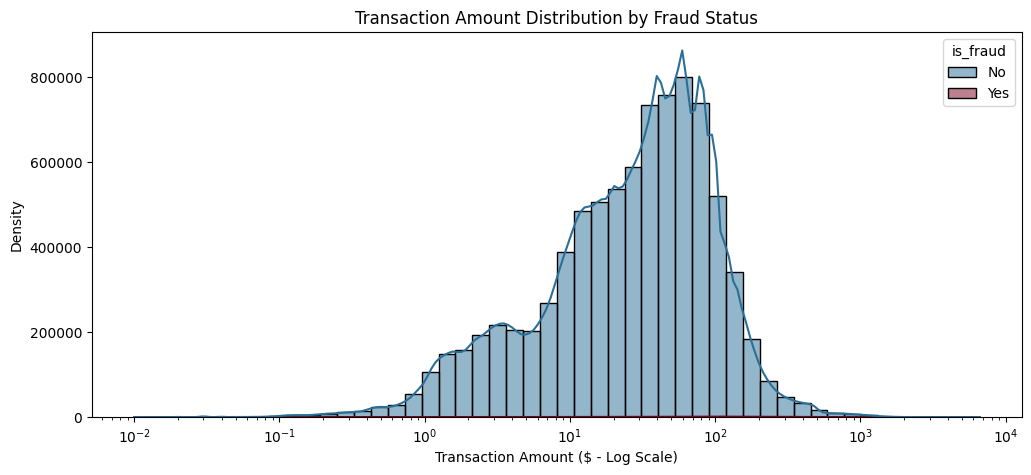

In [ ]:
#Distribution of Transaction Amount 
fig,ax = plt.subplots(figsize = (12,5))
sns.histplot(data=df[df['amount'] > 0], 
    x='amount',
    hue='is_fraud',
    bins=50,
    kde=True,
    log_scale=True,
    common_norm=False,
    palette=['#2a6f97', '#7b0323'],
    ax=ax,
)
ax.set_title('Transaction Amount Distribution by Fraud Status')
ax.set_xlabel('Transaction Amount ($ - Log Scale)')
ax.set_ylabel('Density')
plt.show()

In [ ]:
total_transactions = len(df)
fraud_count = df['is_fraud'].value_counts()
fraud_percentage = (fraud_count / total_transactions) * 100


Total transactions: 13305915
Fraudulent transactions: 13332 (0.10%)
Non-fraudulent transactions: 8901631 (66.90%)



Text(0.5, 1.0, 'Fraudulent vs Non-Fraudulent Transactions')

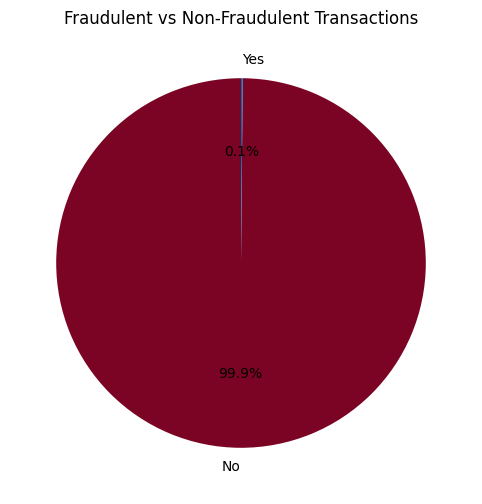

In [ ]:
print(f'''
Total transactions: {total_transactions}
Fraudulent transactions: {fraud_count['Yes']} ({fraud_percentage['Yes']:.2f}%)
Non-fraudulent transactions: {fraud_count['No']} ({fraud_percentage['No']:.2f}%)
''')

fig, ax = plt.subplots(figsize=(8, 6))
plt.pie(fraud_count, labels=fraud_count.index, autopct='%1.1f%%', startangle=90, colors=['#7b0323',"#1461ae"])
ax.set_title('Fraudulent vs Non-Fraudulent Transactions')

([], [])

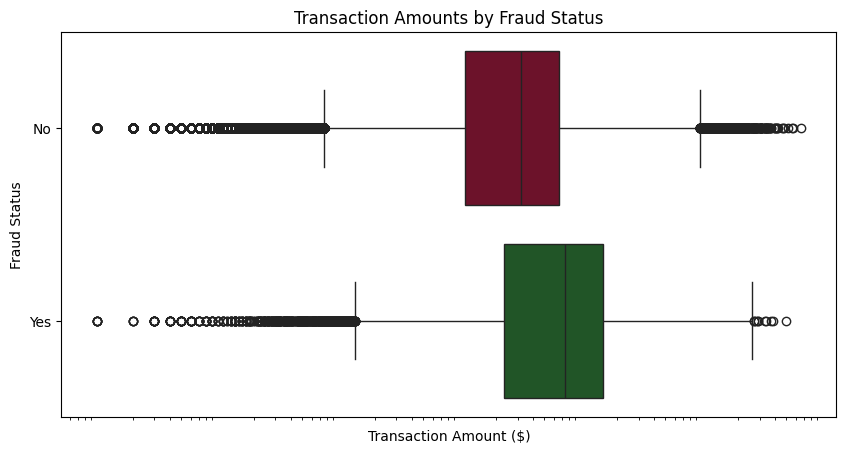

In [ ]:
#Transaction Amounts by Fraud Status
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(y='is_fraud', x='amount', data=df, ax=ax, log_scale=True, palette={'No': '#7b0323', 'Yes': "#195d20"})
ax.set_title('Transaction Amounts by Fraud Status')
ax.set_xlabel('Transaction Amount ($)')
ax.set_ylabel('Fraud Status')
plt.xticks([])

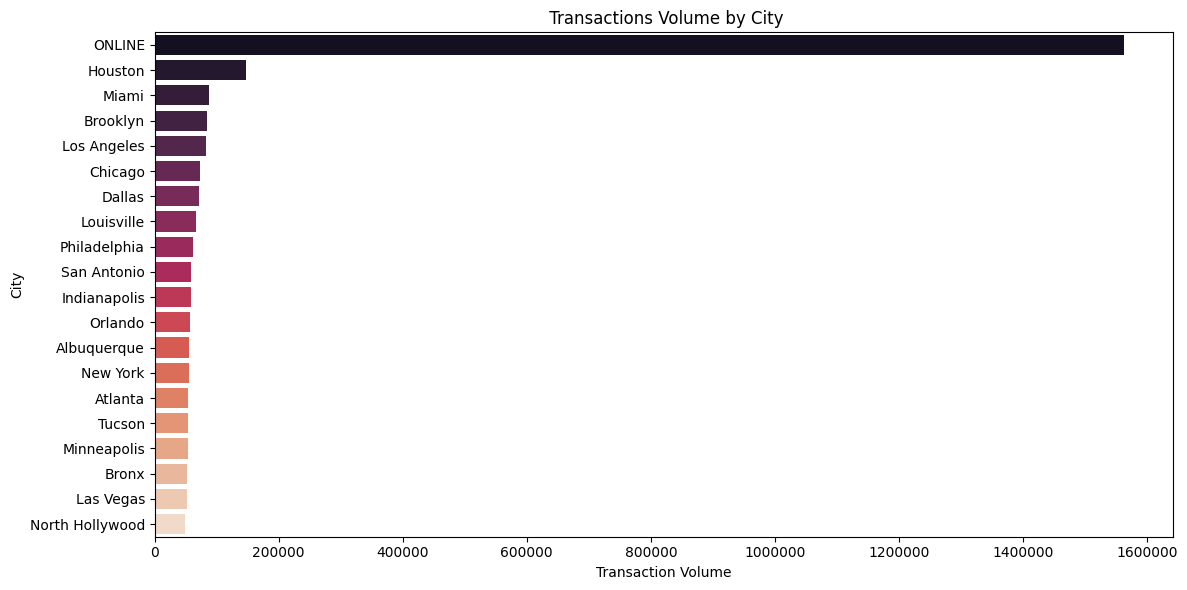

In [ ]:
cities = df[['merchant_city']].dropna()
top20_cities = cities['merchant_city'].value_counts().head(20).index
top_cities = df[df['merchant_city'].isin(top20_cities)]

fig, ax = plt.subplots(figsize=(12, 6))
sns.countplot(y='merchant_city', data=top_cities, order=top20_cities, palette = 'rocket', ax=ax)
ax.set_title(' Transactions Volume by City')
ax.set_xlabel('Transaction Volume')
ax.set_ylabel('City')
ax.ticklabel_format(style='plain', axis='x')

plt.tight_layout()
plt.show()

In [ ]:
fraud_locations = fraud_df.dropna(subset=['latitude', 'longitude'])

if len(fraud_locations) > 0:
    center_lat = fraud_locations['latitude'].mean()
    center_lon = fraud_locations['longitude'].mean()
    
    m = folium.Map(location=[center_lat, center_lon], zoom_start=12)
    heat_data = fraud_locations[['latitude', 'longitude']].values.tolist()
    HeatMap(heat_data, radius=12, blur=8, max_zoom=1).add_to(m)
    display(m)
    
    m.save('fraud_heatmap.html')
else:
    print("No fraud locations with valid coordinates found.")

### **4. Bivariate EDA - Explore Relationships**

Text(0, 0.5, 'Density')

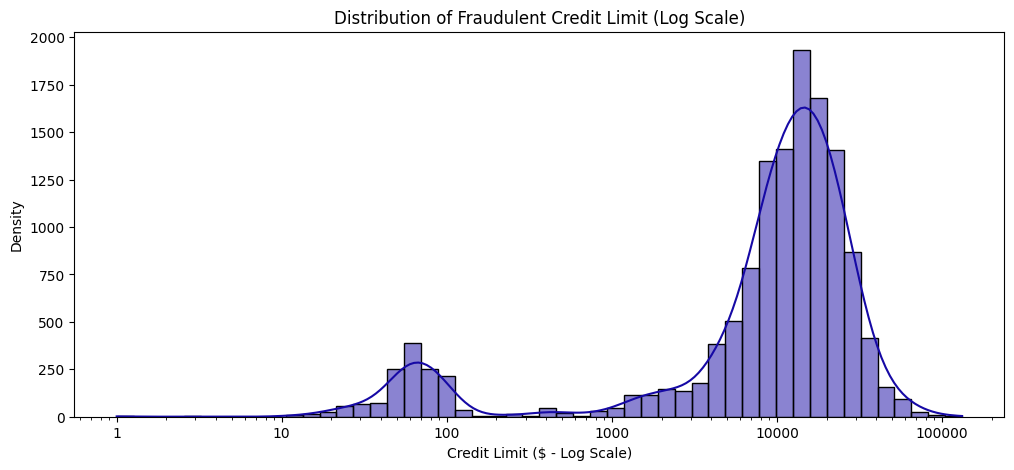

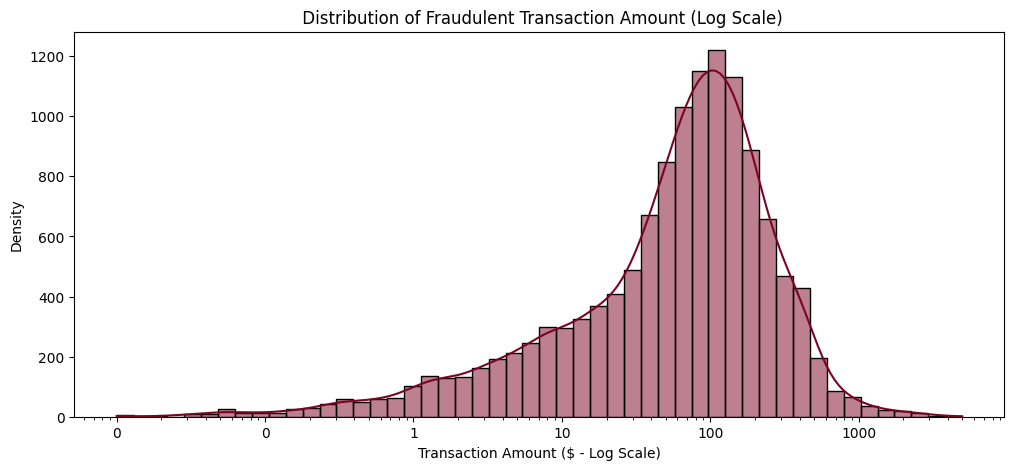

In [ ]:
#Distribution of Credit Limit
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(data=fraud_df[fraud_df['credit_limit']>0], x='credit_limit', bins=50, kde=True, color="#1609a5", log_scale=True, ax=ax)
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.ticklabel_format(style="plain", axis="x")
ax.set_title('Distribution of Fraudulent Credit Limit (Log Scale)')
ax.set_xlabel('Credit Limit ($ - Log Scale)')
ax.set_ylabel('Density')

#Distribution of Transaction Amount
fig, ax= plt.subplots(figsize=(12,5))
sns.histplot(data=fraud_df[fraud_df['amount']>0], x='amount',bins=50, kde=True, color='#7b0323', log_scale=True, ax=ax)
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.ticklabel_format(style="plain", axis="x")
ax.set_title(' Distribution of Fraudulent Transaction Amount (Log Scale)')
ax.set_xlabel('Transaction Amount ($ - Log Scale)')
ax.set_ylabel('Density') 

The utilisation ratio between credit limit and fraudulent transaction amount is both **left-skewed**, dictates the transaction amount spikes near it limits. To conclude, **frauds are attempted on massive max-out purchases** rather than test out cards with smaller transactions. 

Text(0, 0.5, 'Merchant Category Code (MCC)')

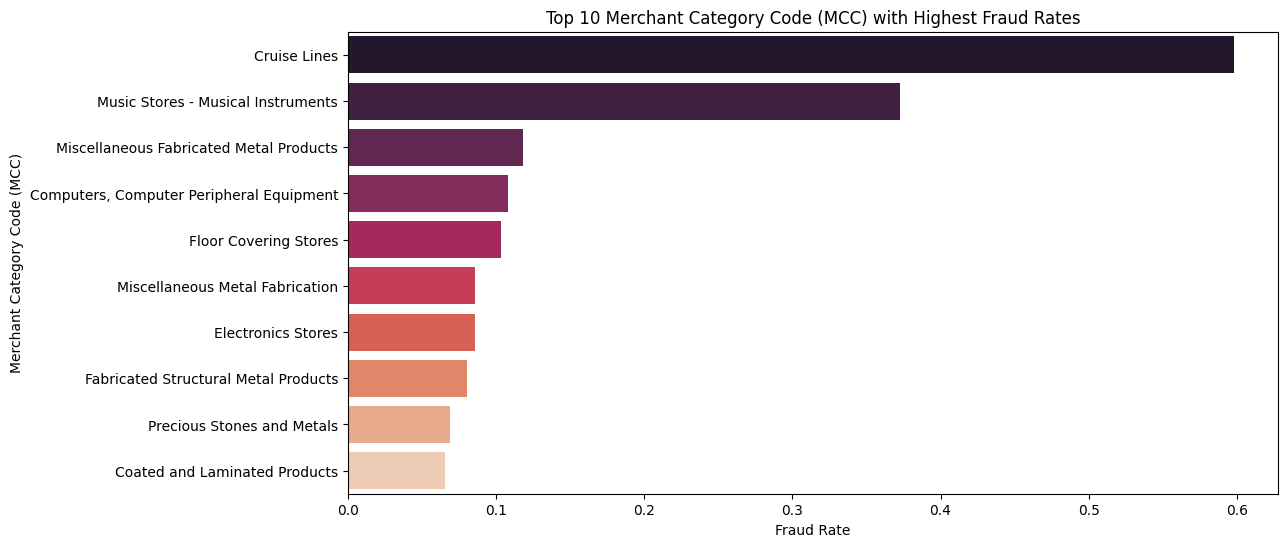

In [ ]:
#Fraud Rate by Merchant Category Code (MCC)
mcc_fraud_rate = df.groupby('description')['is_fraud_numeric'].agg(fraud_rate='mean', total_transactions='count').reset_index()
mcc_fraud_rate = mcc_fraud_rate.merge(mcc_codes, on='description', how='left')
mcc_fraud_rate = mcc_fraud_rate[mcc_fraud_rate['total_transactions'] > 100].sort_values(by='fraud_rate', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x='fraud_rate', y='description', data=mcc_fraud_rate.head(10), ax=ax, palette='rocket')
ax.set_title('Top 10 Merchant Category Code (MCC) with Highest Fraud Rates')
ax.set_xlabel('Fraud Rate')
ax.set_ylabel('Merchant Category Code (MCC)') 

Text(0, 0.5, 'Transaction Errors')

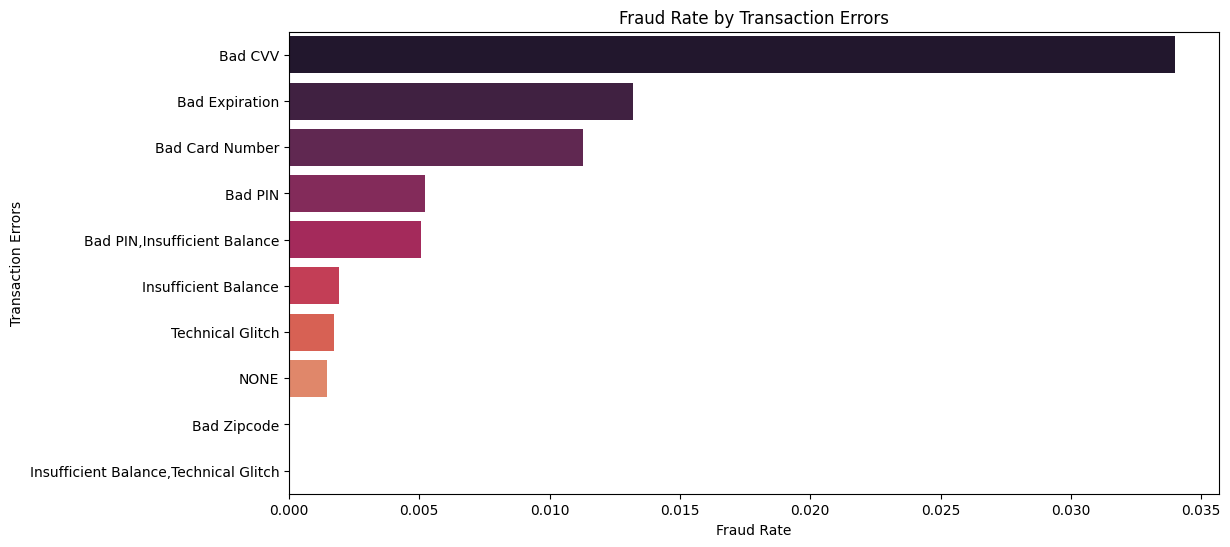

In [ ]:
#Transaction Errors by Fraud Status
error_fraud_rate = df.groupby('errors')['is_fraud_numeric'].agg(fraud_rate='mean', total_transactions='count').reset_index()
error_fraud_rate = error_fraud_rate[error_fraud_rate['total_transactions'] > 50].sort_values(by='fraud_rate', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x='fraud_rate', y='errors', data=error_fraud_rate, ax=ax, palette='rocket')
ax.set_title('Fraud Rate by Transaction Errors')
ax.set_xlabel('Fraud Rate')
ax.set_ylabel('Transaction Errors')


Text(0, 0.5, 'Transaction Type')

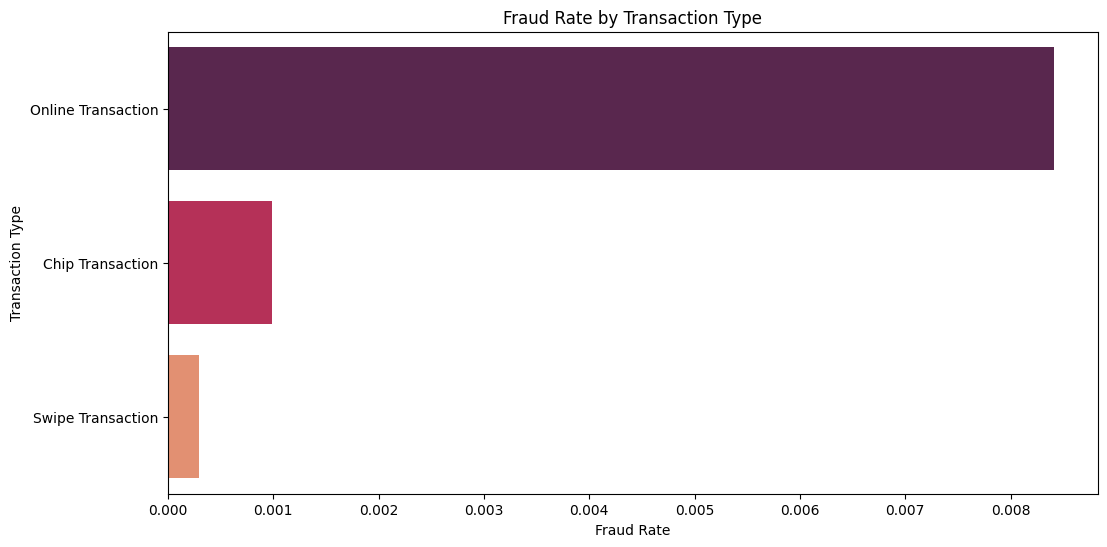

In [ ]:
#Online Transactions by Fraud Status
online_fraud_rate = df.groupby('use_chip')['is_fraud_numeric'].agg(fraud_rate='mean', total_transactions='count').reset_index()
online_fraud_rate = online_fraud_rate[online_fraud_rate['total_transactions'] > 50].sort_values(by='fraud_rate', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x='fraud_rate', y='use_chip', data=online_fraud_rate, ax=ax, palette='rocket')
ax.set_title('Fraud Rate by Transaction Type')
ax.set_xlabel('Fraud Rate')
ax.set_ylabel('Transaction Type')

Transactions encountering specific error codes, occuring within higher risk merchant categories or classifying into transaction type may dictate an exponentially higher fraud probability.

<div class="alert alert-block alert-info">
<b>Summary Insight:</b> 

- Out of 13,305,915 recorded transactions, only <b>0.1% is fraudulent</b>, making the identification of distinct behavioral signatures are critical. 
- Fraudulent attempts usually <b>exceed normal spending threshold</b>, indicating fraudsters target massive max-out transactions rather than micro-transactions. 
- Fraud is <b>not distributed evenly across industries</b>, expensive merchant categories such as cruise lines, musical instruments, experience higher fraud rates than others.
- The presence of <b>misinformation errors (eg. Bad CVV), strongly correlates with blocked or malicious transaction attempts</b> compared to standard 'NONE' response. 
- Fraud also <b>concentrates heavily within urban areas and big cities </b> (eg. Los Angeles, New York,...) rather than rural areas. 


</div>

## **IV. Data Preprocessing**

**Credit Utilisation Ratio** is the proportion of total credit limit that the user owns as an active balance. Calculating the proportions and add the utilisation as a feature could help the model achieve better results. 

In [49]:
df['utilisation'] = df['amount'] / df['credit_limit']

Before splitting data into train and test dataset, dropping unrelevant columns and ensuring all categorical features are encoded effectively is necessary. 

In [50]:
#Define features
num_features = ['amount', 'latitude', 'longitude', 'credit_limit', 'utilisation']
cat_features = ['use_chip', 'card_type', 'mcc','errors']

#Build dataframe
X = df[num_features + cat_features].copy()
y = df['is_fraud_numeric'].copy()

In [51]:
#Replace infinity values (dividing by 0 error)
X.replace([np.inf, -np.inf], np.nan, inplace=True)

#Handle missing values
X[num_features] = X[num_features].fillna(X[num_features].median())
X[cat_features] = X[cat_features].fillna('UNKNOWN')
valid_idx = y.dropna().index
X= X.loc[valid_idx]
y = y.loc[valid_idx].astype(int)

#One hot encoding for new dataframe
X= pd.get_dummies(X, columns=cat_features, drop_first=True)

X.columns = [re.sub(r"[^A-Za-z0-9_]+", "_", str(col)) for col in X.columns]

In [52]:
X.info()
y.info()

<class 'pandas.DataFrame'>
Index: 8914963 entries, 0 to 13305912
Columns: 139 entries, amount to errors_Technical_Glitch
dtypes: bool(134), float64(4), int64(1)
memory usage: 1.5 GB
<class 'pandas.Series'>
Index: 8914963 entries, 0 to 13305912
Series name: is_fraud_numeric
Non-Null Count    Dtype
--------------    -----
8914963 non-null  int64
dtypes: int64(1)
memory usage: 136.0 MB


In [26]:
#Train - Test split 
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42,
    stratify=y)

In [44]:
print(X_train.shape, X_test.shape)

(7131970, 139) (1782993, 139)


## **4. Model Training and Model Evaluation**

<div class="alert alert-block alert-info">
<b>Model Selection:</b> 

The EDA has revealed several distinct structural characteristics in the dataset. To build a high-performing fraud detection system, the choice of algorithms must adress these requirements:
- The features contains both numerical and categorical variables. Therefore, <b>tree-based method</b> would be a better choice for this mixed dataset, rather than linear models, which require feature scaling and extensively learn hierarchical splits across categorical variables.
- As seen from several observations, fraudulent transactions occur with specific behaviors. <b>Gradient Boosting</b>, which correcting the residual errors from previous trees, might effectively points out subtle and complex fraud signatures.
- The class distribution of the dataset confirmed a severe imbalance. <b>Random Forest</b> and <b>XGBoost</b> helps resisting overfitting and tuning with custom evaluation metrics to optimise the detection threshold. 

<b>In this section, Logistic Regression and robust tree-based benchmarks are the baseline. Ultimately, to handle heavy data volume and maximise efficiency, LightGBM will be used to scale the pipeline and weigh classes to achieve optimal performance. </b>

</div>

In [56]:
#Run this to import libraries for the models
%pip install --upgrade pip
%pip install lightgbm
import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,)

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [54]:
#Initialise LightGBM model
model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)

model.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 10666, number of negative: 7121304
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.102788 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1520
[LightGBM] [Info] Number of data points in the train set: 7131970, number of used features: 130
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


**Receiver Operating Characteristic - Area Under the Curve (ROC-AUC)** is a standard evaluation metric used to evaluate how well a classification model can distinguish between two classes:
- ROC Curve: plots a model's True Positive Rate against its False Positive Rate across possible classification threshold.
- AUC (area under the curve): the number measures the area underneath that curve (1.0 = perfectly seperate true and false positive, 0.5 = no better than random guess).

In this case, ROC-AUC is vital for the dataset due to its classification imbalance characteristics. ROC-AUC plots a graph actual fraud correctly caught vs. legitimate fraud incorrectly flagged as fraud across possible threshold and score the model's accuracy. 

In [47]:
# Predict classes and probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate metrics
roc_auc = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC Score: {roc_auc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

ROC-AUC Score: 0.9579

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.94      0.97   1780327
           1       0.02      0.85      0.04      2666

    accuracy                           0.94   1782993
   macro avg       0.51      0.89      0.50   1782993
weighted avg       1.00      0.94      0.97   1782993



<div class="alert alert-block alert-info">
<b>Interpretation:</b> 

The Classification Report shows statistics of <b>legitimate transactions (Class 0)</b> and <b>fraudulent transaction (Class 1)</b>, evaluated on a test set of <b>N = 1782993</b> at a <b>classification threshold of 0.5</b>.

Based on the Classification Report:
- <b>ROC-AUC Score is high (ROC-AUC=0.9579)</b>. This indicates that the features contain, strong signals that differentiate fraud from normal behaviour.
- <b>Fraud Recall for Class I is good (recall=0.85)</b>. Out of 100 actual fraudulent transaction, the model caught 85 of them. 
- <b>Fraud Precision for Class I achieved a very low percentage (precision=0.02)</b>. This means the false positive proportion still quite high.

In conclusion, the model correctly flagged real fraud. However, 15% of fraud is still missed and a massive amount of legitimate transactions were mistaken as fraud. These represents direct financial losses, chargeback costs or custommer friction.

</div>

The code below helps adjust the classification threshold to something stricter (from 0.5 to 0.8) to reduce false alarms and boost the precision. 

In [60]:
# Predict classes and probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Set a custom threshold
custom_threshold = 0.8

# Convert probabilities to binary predictions based on the new threshold
y_pred_custom = (y_prob >= custom_threshold).astype(int)

# Calculate metrics
print("Classification Report:")
print(classification_report(y_test, y_pred_custom))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99   1780327
           1       0.05      0.73      0.10      2666

    accuracy                           0.98   1782993
   macro avg       0.53      0.85      0.54   1782993
weighted avg       1.00      0.98      0.99   1782993



When the classification threshold increased to 0.8, the precision of the model also rises to 0.05. However, the recall score decreases to 0.73. Even though the false positve rate went down, there is now more missed actual fraud. 

Therefore, the threshold depends largely on the business priorities and financial risks. 

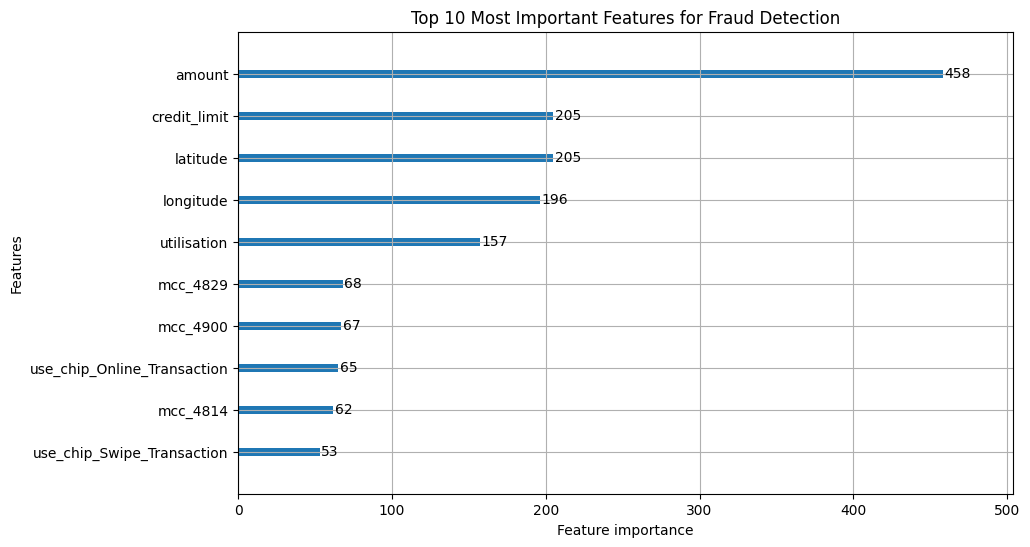

In [57]:
#Plot importance value of features
lgb.plot_importance(model, max_num_features=10, figsize=(10, 6))
plt.title("Top 10 Most Important Features for Fraud Detection")
plt.show()

The `amount` feature is the most important indicator. This confirms that abnormal or high value transactions are primary signals for fraudulent activity.

`credit_limit` along with `latitude` and `longtitude` are second. This highlights that fraud activity often operate across specific coordinates and push the credit amount to their limits.

## **5. Software Engineering & Cloud Deployment**

This is the final step of the project. 

The model and the data structures will be saved from this notebook into seperate coding files for functional use. 

The code below is for saving the model and data structures. If the model and data strutures files are already existed in your zip folder, I suggest not to alter the code or run it again (in case of cloud crashing). 

In [64]:
import joblib
%pip install fastapi
from fastapi import FastAPI

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 19.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [fastapi]8/10 [pydantic]
Note: you may need to restart the kernel to use updated packages.


In [63]:
#Save the trained model
joblib.dump(model, 'fraud_model.pkl')
print('Model saved.')

Model saved.


In [65]:
#Save the data structures
model_cols = list(X_train.columns)
joblib.dump(model_cols, 'model_columns.pkl')
print('Feature columns saved.')

Feature columns saved.
